In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [ ]:
import kagglehub

path = kagglehub.dataset_download("bhavikjikadara/mental-health-dataset")
print(path)



100%|██████████| 1.95M/1.95M [00:00<00:00, 102MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/bhavikjikadara/mental-health-dataset/versions/1


In [ ]:
import os

os.listdir(path)


['Mental Health Dataset.csv']

In [ ]:
import pandas as pd
import os

csv_file = os.listdir(path)[0]   # auto-pick first CSV
df = pd.read_csv(os.path.join(path, csv_file))

df.head()


,Timestamp,Gender,Country,Occupation,self_employed,family_history,treatment,Days_Indoors,Growing_Stress,Changes_Habits,Mental_Health_History,Mood_Swings,Coping_Struggles,Work_Interest,Social_Weakness,mental_health_interview,care_options
0,8/27/2014 11:29,Female,United States,Corporate,NaN,No,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Not sure
1,8/27/2014 11:31,Female,United States,Corporate,NaN,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,No
2,8/27/2014 11:32,Female,United States,Corporate,NaN,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Yes
3,8/27/2014 11:37,Female,United States,Corporate,No,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,Maybe,Yes
4,8/27/2014 11:43,Female,United States,Corporate,No,Yes,Yes,1-14 days,Yes,No,Yes,Medium,No,No,Yes,No,Yes


In [ ]:
df.drop(columns=['Timestamp'], inplace=True)


In [ ]:
# Replace missing values with mode (most frequent)
df.fillna(df.mode().iloc[0], inplace=True)


In [ ]:
binary_map = {
    'Yes': 1,
    'No': 0,
    'Maybe': 0.5,
    'Not sure': 0.5
}

binary_cols = [
    'self_employed', 'family_history', 'treatment',
    'Growing_Stress', 'Changes_Habits',
    'Mental_Health_History', 'Coping_Struggles',
    'Work_Interest', 'Social_Weakness',
    'mental_health_interview', 'care_options'
]

for col in binary_cols:
    df[col] = df[col].map(binary_map)


In [ ]:
days_map = {
    '1-14 days': 1,
    '15-30 days': 2,
    '31-60 days': 3,
    'More than 60 days': 4
}
df['Days_Indoors'] = df['Days_Indoors'].map(days_map)


In [ ]:
mood_map = {
    'Low': 1,
    'Medium': 2,
    'High': 3
}
df['Mood_Swings'] = df['Mood_Swings'].map(mood_map)


In [ ]:
df = pd.get_dummies(
    df,
    columns=['Gender', 'Country', 'Occupation'],
    drop_first=True
)


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('treatment', axis=1)
y = df['treatment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [ ]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)


RandomForestClassifier(random_state=42)

Accuracy: 0.7347835753253639
              precision    recall  f1-score   support

         0.0       0.75      0.70      0.72     28895
         1.0       0.73      0.77      0.75     29578

    accuracy                           0.73     58473
   macro avg       0.74      0.73      0.73     58473
weighted avg       0.74      0.73      0.73     58473



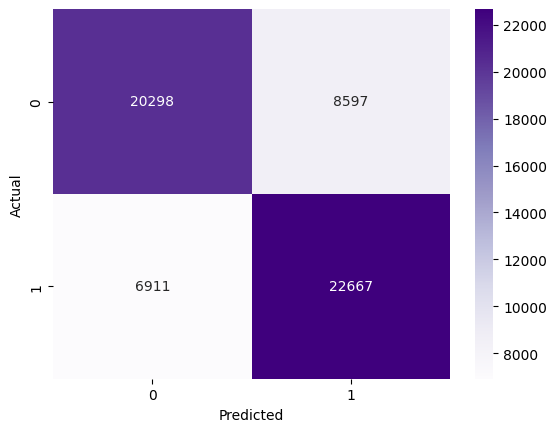

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [ ]:
importances = model.feature_importances_
features = X.columns

imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

imp_df.head(10)


,Feature,Importance
11,care_options,0.230231
1,family_history,0.229871
10,mental_health_interview,0.066804
0,self_employed,0.055590
12,Gender_Male,0.047426
45,Country_United Kingdom,0.028764
46,Country_United States,0.024468
28,Country_Ireland,0.023526
16,Country_Canada,0.020442
6,Mood_Swings,0.016113


from matplotlib import pyplot as plt
_df_0['index'].plot(kind='hist', bins=20, title='index')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['Importance'].plot(kind='hist', bins=20, title='Importance')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2.plot(kind='scatter', x='index', y='Importance', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3['index'].plot(kind='line', figsize=(8, 4), title='index')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_4['Importance'].plot(kind='line', figsize=(8, 4), title='Importance')
plt.gca().spines[['top', 'right']].set_visible(False)

In [ ]:
def predict_mental_health_fixed(input_dict):
    import pandas as pd

    # Create empty dataframe with all model features
    input_df = pd.DataFrame(0, index=[0], columns=X.columns)

    # Fill only provided inputs
    for key, value in input_dict.items():
        if key in input_df.columns:
            input_df.at[0, key] = value

    prediction = model.predict(input_df)[0]
    probability = model.predict_proba(input_df)[0][1]

    return prediction, probability


In [ ]:
sample_input = {
    'self_employed': 0,
    'family_history': 1,
    'Growing_Stress': 1,
    'Changes_Habits': 1,
    'Mental_Health_History': 1,
    'Mood_Swings': 2,        # Medium
    'Coping_Struggles': 1,
    'Work_Interest': 0,
    'Social_Weakness': 1,
    'mental_health_interview': 0,
    'care_options': 1,
    'Days_Indoors': 2,       # 15–30 days
    'Gender_Male': 0         # Female
}

pred, prob = predict_mental_health_fixed(sample_input)

print("Prediction:", "Needs Support" if pred == 1 else "Low Risk")
print("Risk Probability:", round(prob * 100, 2), "%")


Prediction: Needs Support
Risk Probability: 96.8 %


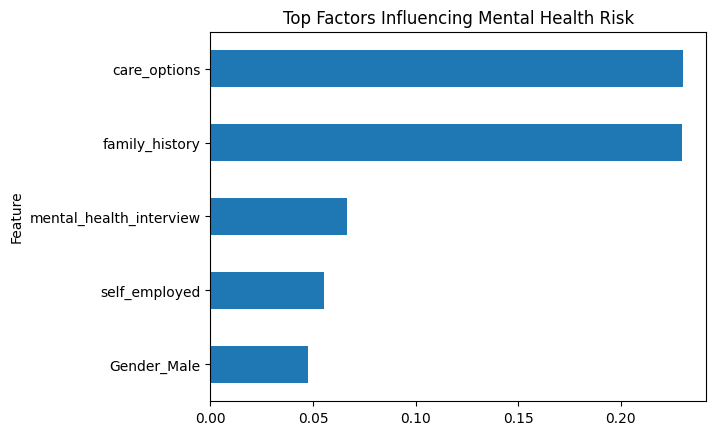

In [ ]:
imp_df.head(5).plot(
    kind='barh',
    x='Feature',
    y='Importance',
    legend=False,
    title='Top Factors Influencing Mental Health Risk'
)
plt.gca().invert_yaxis()
plt.show()
